# EDA 03 — Taiwan Default of Credit Card Clients

Nguồn: UCI (Yeh & Lien, 2009) — 30.000 chủ thẻ tín dụng tại Đài Loan, lịch sử 6 tháng (04–09/2005).
Nhãn gốc `default.payment.next.month` → `target`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.visualization import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
INTERIM = ROOT / "data" / "interim"

## 1. Nạp dữ liệu

In [2]:
NAME = "taiwan_default_credit"
df = pd.read_csv(INTERIM / "taiwan_default_credit.csv")
df.shape

(30000, 25)

## 2. Tổng quan

In [3]:
ov = eda.overview(df)
display(ov.to_frame("value"))
display(df.head())

,value
rows,30000.0
features,24.0
numeric_features,24.0
categorical_features,0.0
duplicate_rows,0.0
cells_missing_pct,0.0
features_with_missing,0.0


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,target
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## 3. Nhãn (target: 1 = xấu / vỡ nợ, 0 = tốt)

{'n': 30000, 'n_bad': 6636, 'n_good': 23364, 'bad_rate_pct': 22.12, 'imbalance_ratio': 3.52}


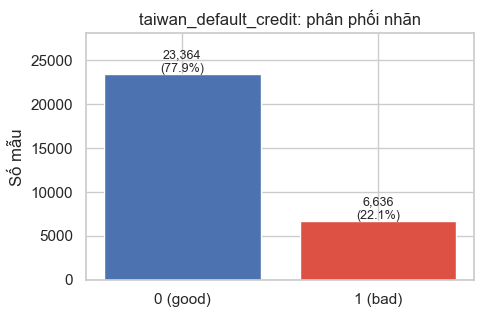

In [4]:
tgt = eda.target_summary(df["target"])
print(tgt)
eda.plot_target(df["target"], NAME)

## 4. Giá trị thiếu

Bảng thứ hai so sánh tỉ lệ nợ xấu khi cột bị thiếu và khi có giá trị: chênh lệch lớn nghĩa là *bản thân việc thiếu* đã mang thông tin về nhãn.

In [5]:
miss = eda.missing_table(df)
display(miss if len(miss) else "Không có giá trị thiếu (NaN).")
mvt = eda.missing_vs_target(df)
display(mvt if len(mvt) else "Không có cột nào đủ lượng thiếu để so sánh bad rate.")

'Không có giá trị thiếu (NaN).'

'Không có cột nào đủ lượng thiếu để so sánh bad rate.'

## 5. Hồ sơ các biến số

`skew`/`kurtosis`: độ lệch và độ nhọn; `outlier_iqr_pct`: % điểm nằm ngoài 1.5×IQR; `zero_pct`: % giá trị 0; `auc`: AUC đơn biến (max(AUC, 1−AUC)) — thước đo nhanh sức phân biệt của từng biến.

In [6]:
prof = eda.numeric_profile(df)
cols_show = ["n_unique", "min", "median", "max", "skew", "kurtosis", "outlier_iqr_pct", "zero_pct", "auc"]
display(prof.sort_values("auc", ascending=False)[cols_show])
print("Số cột số có |skew| > 2:", int((prof["skew"].abs() > 2).sum()), "/", len(prof))

,n_unique,min,median,max,skew,kurtosis,outlier_iqr_pct,zero_pct,auc
feature,,,,,,,,,
PAY_0,11,-2.0,0.0,8.0,0.732,2.720,10.433,49.123,0.690
PAY_2,11,-2.0,0.0,8.0,0.791,1.570,14.700,52.433,0.639
PAY_3,11,-2.0,0.0,8.0,0.841,2.084,14.030,52.547,0.624
LIMIT_BAL,81,10000.0,140000.0,1000000.0,0.993,0.536,0.557,0.000,0.618
PAY_AMT1,7943,0.0,2100.0,873552.0,14.668,415.185,9.150,17.497,0.611
PAY_4,11,-2.0,0.0,8.0,1.000,3.496,11.693,54.850,0.610
PAY_AMT2,7899,0.0,2009.0,1684259.0,30.452,1641.358,9.047,17.987,0.605
PAY_5,10,-2.0,0.0,8.0,1.008,3.989,9.893,56.490,0.600
PAY_AMT3,7518,0.0,1800.0,896040.0,17.216,564.217,8.660,19.893,0.597


Số cột số có |skew| > 2: 12 / 23


## 6. Phân phối theo nhãn

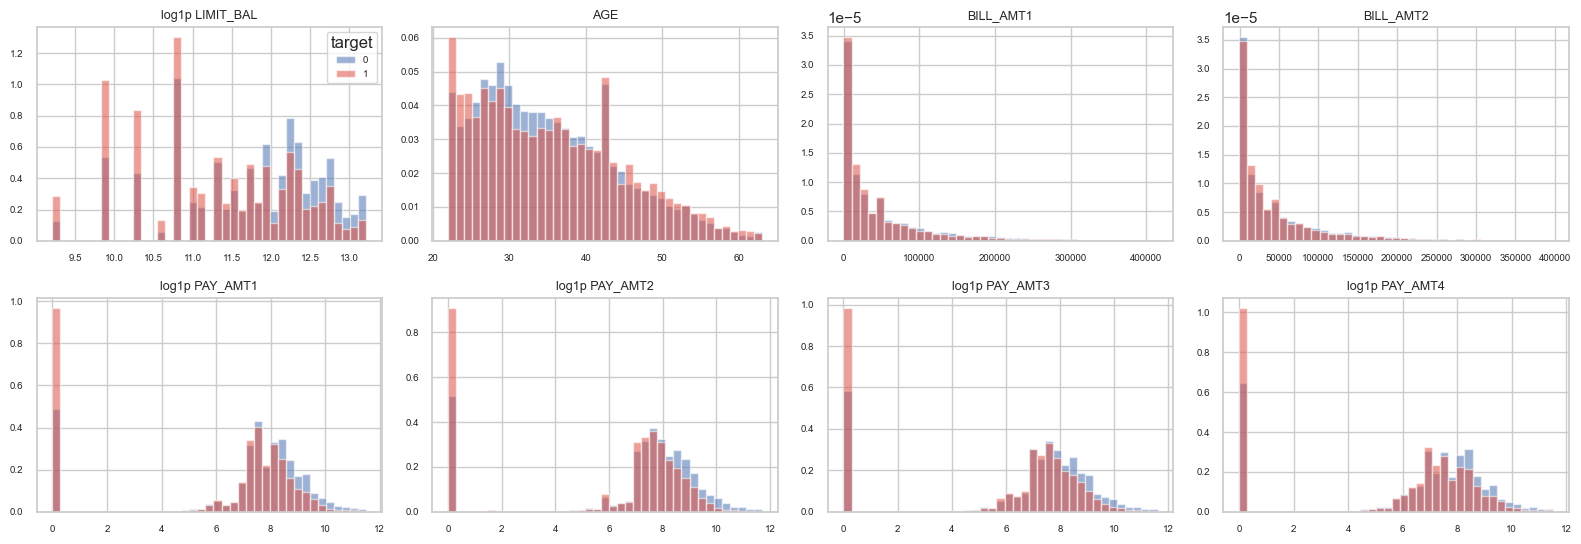

In [7]:
num = ["LIMIT_BAL", "AGE", "BILL_AMT1", "BILL_AMT2", "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4"]
eda.plot_numeric_by_target(df, num, NAME, log=["LIMIT_BAL", "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4"])

## 7. Biến phân loại: tỉ lệ nợ xấu theo nhóm

Đường nét đứt = bad rate chung.

n  bad_rate  share_pct
feature   level                            
SEX       1      11888     24.17      39.63
          2      18112     20.78      60.37
EDUCATION 0         14      0.00       0.05
          1      10585     19.23      35.28
          2      14030     23.73      46.77
          3       4917     25.16      16.39
          4        123      5.69       0.41
          5        280      6.43       0.93
          6         51     15.69       0.17
MARRIAGE  0         54      9.26       0.18
          1      13659     23.47      45.53
          2      15964     20.93      53.21
          3        323     26.01       1.08
PAY_0     -2      2759     13.23       9.20
          -1      5686     16.78      18.95
          0      14737     12.81      49.12
          1       3688     33.95      12.29
          2       2667     69.14       8.89
          3        322     75.78       1.07
          4         76     68.42       0.25
          5         26     50.00       0.09
          6         11     54.55       0.04
          7          9     77.78       0.03
          8         19     57.89       0.06
PAY_2     -2      3782     18.27      12.61
          -1      6050     15.97      20.17
          0      15730     15.91      52.43
          1         28     17.86       0.09
          2       3927     55.61      13.09
          3        326     61.66       1.09
          4         99     50.51       0.33
          5         25     60.00       0.08
          6         12     75.00       0.04
          7         20     60.00       0.07
          8          1      0.00       0.00
PAY_6     -2      4895     20.04      16.32
          -1      5740     16.99      19.13
          0      16286     18.84      54.29
          2       2766     50.65       9.22
          3        184     64.13       0.61
          4         49     63.27       0.16
          5         13     53.85       0.04
          6         19     73.68       0.06
          7         46     82.61       0.15
          8          2    100.00       0.01

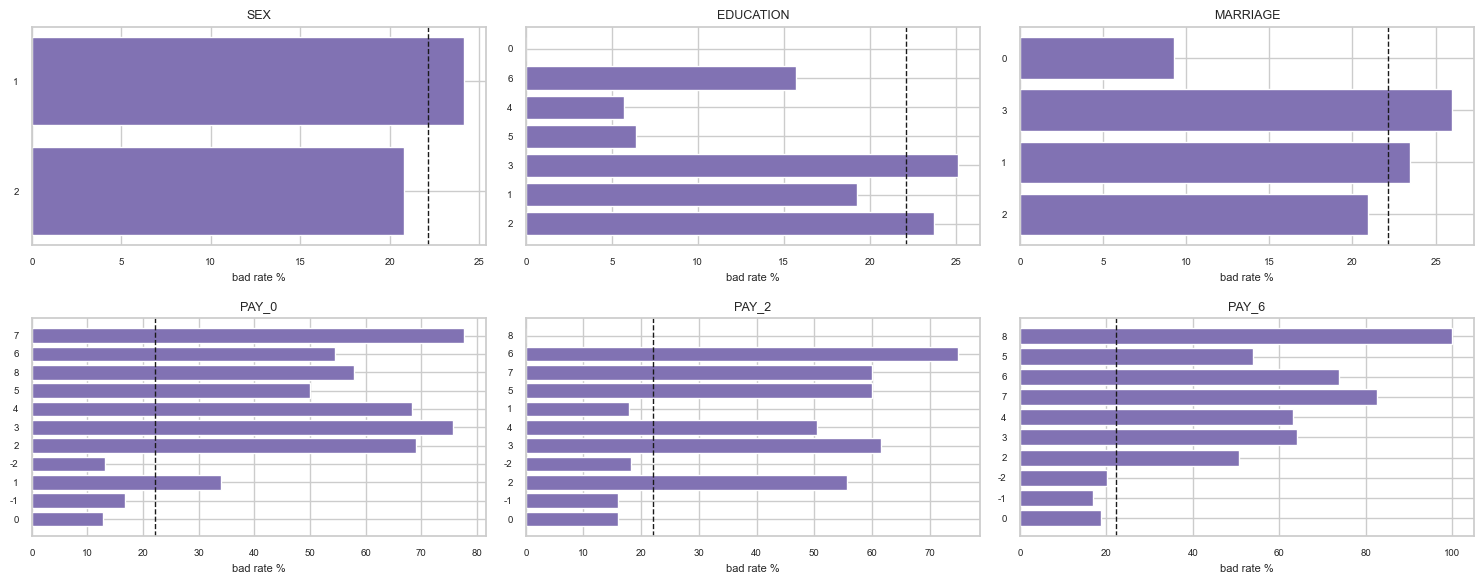

In [8]:
cats = ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_6"]
display(eda.categorical_bad_rate(df, cats))
eda.plot_categorical_bad_rate(df, cats, NAME)

## 8. Tương quan

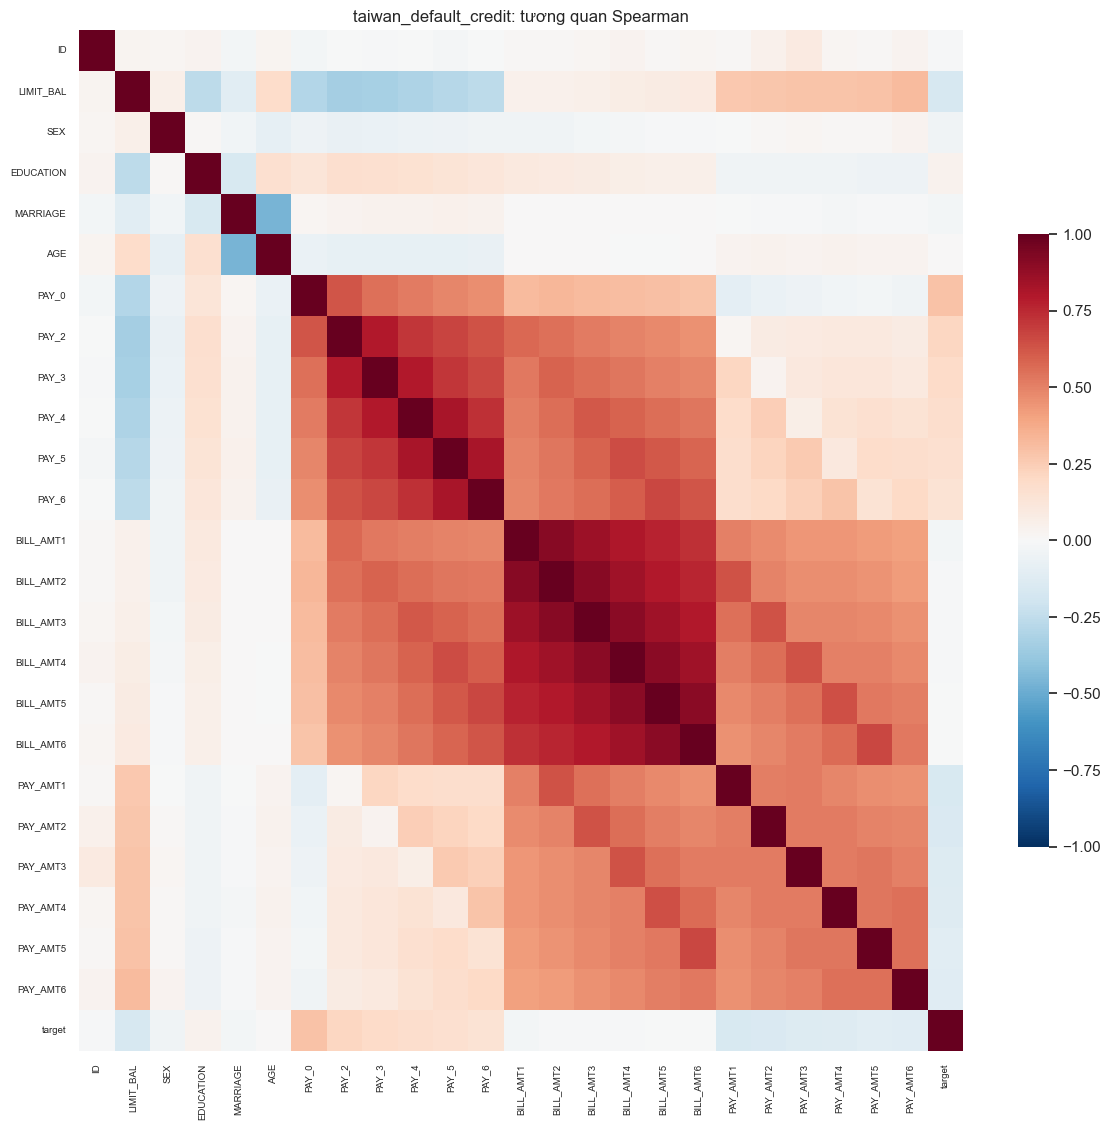

,a,b,spearman
0,BILL_AMT1,BILL_AMT2,0.911133
1,BILL_AMT2,BILL_AMT3,0.907740
2,BILL_AMT3,BILL_AMT4,0.903640
3,BILL_AMT4,BILL_AMT5,0.902787
4,BILL_AMT5,BILL_AMT6,0.902097


In [9]:
corr = eda.correlation_heatmap(df, NAME)
display(eda.high_corr_pairs(corr, thr=0.9).head(20))

## 9. Kiểm tra riêng cho bộ dữ liệu

### Mã không có trong tài liệu gốc

In [10]:
print("EDUCATION:", df["EDUCATION"].value_counts().sort_index().to_dict(), "(tài liệu chỉ có 1–4)")
print("MARRIAGE :", df["MARRIAGE"].value_counts().sort_index().to_dict(), "(tài liệu chỉ có 1–3)")
print("PAY_0    :", df["PAY_0"].value_counts().sort_index().to_dict(), "(tài liệu không định nghĩa -2 và 0)")
neg = (df.filter(like="BILL_AMT") < 0).any(axis=1)
print(f"Dòng có BILL_AMT âm (trả thừa): {neg.mean():.1%}")
print("Cột ID có AUC ~0.5 — chỉ là khoá, cần loại khỏi đặc trưng.")

EDUCATION: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51} (tài liệu chỉ có 1–4)
MARRIAGE : {0: 54, 1: 13659, 2: 15964, 3: 323} (tài liệu chỉ có 1–3)
PAY_0    : {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19} (tài liệu không định nghĩa -2 và 0)
Dòng có BILL_AMT âm (trả thừa): 6.4%
Cột ID có AUC ~0.5 — chỉ là khoá, cần loại khỏi đặc trưng.


## 10. Nhận xét

- **Nhãn:** bad rate ≈ **22%** (6.636/30.000), tỉ lệ ≈ 3,5:1 — mất cân bằng vừa phải.
- **Nhãn phụ thuộc rất mạnh vào trạng thái trả nợ gần nhất `PAY_0`:** bad rate nhảy từ ~13% (trả đúng hạn) lên ~34% (trễ 1 tháng) và ~70% (trễ ≥ 2 tháng). Bài toán gần như “dự đoán tháng sau dựa trên tháng này” — một biến chiếm phần lớn tín hiệu.
- **Dữ liệu bất thường về mã hoá:** `EDUCATION` có giá trị 0, 5, 6 và `MARRIAGE` có 0 không được mô tả; `PAY_*` có -2 và 0 không có trong tài liệu gốc. Cần gộp/diễn giải lại.
- **Độ lệch cực lớn** ở các khoản thanh toán `PAY_AMT*` (skew 10–30, kurtosis tới >1.600) và dư nợ `BILL_AMT*` (skew ≈ 3, có giá trị âm ở ~6% dòng). Nên dùng log hoặc mô hình cây.
- `BILL_AMT1..6` tương quan rất cao với nhau (ρ > 0,9) → đa cộng tuyến. Không có missing, không có dòng trùng.

In [11]:
EXTRA = {}
eda.save_summary(NAME, {
    "name": NAME,
    "overview": ov.to_dict(),
    "target": tgt,
    "missing_top": miss["missing_pct"].head(10).to_dict() if len(miss) else {},
    "n_numeric_abs_skew_gt2": int((prof["skew"].abs() > 2).sum()),
    "n_numeric": int(len(prof)),
    "max_abs_skew": float(prof["skew"].abs().max()),
    "top_auc": prof["auc"].sort_values(ascending=False).head(5).to_dict(),
    **EXTRA,
})